# AI and ML: a time-aware baseline

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/27-ai-validation.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/27-ai-validation.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `6fffc37cf13dbdd875477b400754d418e1f8c571063f6e212a9ec8aaa3d74f1f`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# AI and ML: a time-aware baseline

**Lesson 27 · Original synthetic data · Independent educational project**

## Objectives

Fit a simple regression with held-out future samples; detect temporal leakage.

[Previous](26-data-lake.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/27-ai-validation.ipynb) · [Next](28-regional-extremes.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=27-ai-validation.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

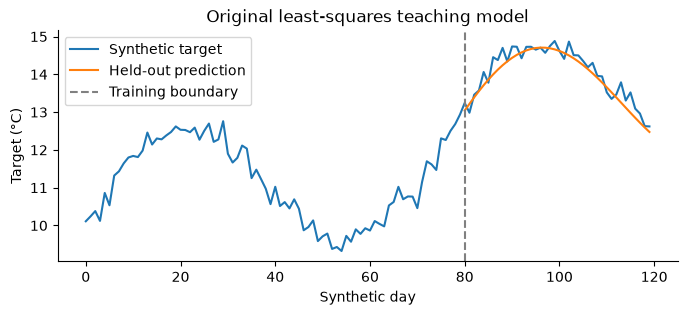

Future RMSE 0.228; training-mean baseline 2.946 °C


In [2]:
rng = np.random.default_rng(23)
day = np.arange(120)
feature = np.sin(day/12)
target = 10 + .03*day + 2*feature + rng.normal(0, .2, len(day))
design = np.column_stack([np.ones(len(day)), day, feature])
split = 80
coef, *_ = np.linalg.lstsq(design[:split], target[:split], rcond=None)
pred = design[split:] @ coef
rmse = np.sqrt(np.mean((pred-target[split:])**2))
baseline_rmse = np.sqrt(np.mean((target[:split].mean()-target[split:])**2))
assert day[:split].max() < day[split:].min()
assert rmse < baseline_rmse
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(day, target, label="Synthetic target")
ax.plot(day[split:], pred, label="Held-out prediction")
ax.axvline(split, color="gray", linestyle="--", label="Training boundary")
ax.set(xlabel="Synthetic day", ylabel="Target (°C)", title="Original least-squares teaching model")
ax.legend(); plt.show()
print(f"Future RMSE {rmse:.3f}; training-mean baseline {baseline_rmse:.3f} °C")

## Exercise

Remove the time feature and compare held-out error. Introduce a regime shift after day 80 and explain why training fit does not guarantee future skill.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

AI/ML tools can connect to digital-twin workflows, but validation must match the intended decision. This small least-squares model demonstrates time separation; it is not a trained DestinE AI model and makes no real forecast claim. MLOps Studio is separately described in the [official Data Lake documentation](https://destine-data-lake-docs.data.destination-earth.eu/en/latest/).

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/ai-in-destination-earth/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).